# Poisson NOTEARS with \(p\)-specific parameters and selectable seeds

This notebook runs unscaled Poisson NOTEARS on the existing datasets in:

```text
simulation_data_25/
simulation_data_50/
simulation_data_75/
```

It uses the following fixed settings:

| \(p\) | `lambda1` | edge threshold |
|---:|---:|---:|
| 25 | 0.0009 | 0.30 |
| 50 | 0.0009 | 0.40 |
| 75 | 0.0020 | 0.30 |

The seed set is controlled from the configuration cell:

```python
SEEDS_TO_RUN = list(range(1, 11))   # seeds 1 through 10
SEEDS_TO_RUN = list(range(1, 51))   # seeds 1 through 50
SEEDS_TO_RUN = [1, 3, 8, 20]        # selected seeds
SEEDS_TO_RUN = None                  # every available seed
```

The notebook does not regenerate or scale the data. Each fitted graph is
saved immediately, so rerunning with `OVERWRITE=False` reuses completed
results.


In [1]:
# ============================================================
# 1. Imports and project location
# ============================================================

from pathlib import Path
import re
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln
from IPython.display import display

# Locate the ZIO repository whether Jupyter starts at ZIO/ or its parent.
PROJECT_DIR = Path("ZIO")
if not (PROJECT_DIR / "code" / "helper" / "linear.py").exists():
    if (Path("code") / "helper" / "linear.py").exists():
        PROJECT_DIR = Path(".")
    else:
        raise FileNotFoundError("Run Jupyter from ZIO/ or the folder containing ZIO/.")
PROJECT_DIR = PROJECT_DIR.resolve()
ROOT = PROJECT_DIR / "code" / "helper"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from linear import notears_linear

print("Project directory:", PROJECT_DIR)
print("Imported notears_linear successfully.")

Project directory: E:\Study\UT-Dallas\Woody\Project 2\notears-master\notears
Imported notears_linear successfully.


In [4]:
# ============================================================
# 2. Configuration
# ============================================================

DATA_FOLDERS_BY_P = {
    25: PROJECT_DIR / "data" / "simulation_data_25",
    50: PROJECT_DIR / "data" / "simulation_data_50",
    75: PROJECT_DIR / "data" / "simulation_data_75",
}

ZERO_INFLATION_PCT = 50

RESULT_DIR = PROJECT_DIR / "output" / "simulation" / "4.1" / "notears_poisson_results_tuned_final"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# p-specific NOTEARS parameters
PARAMS_BY_P = {
    25: {
        "lambda1": 0.0009,
        "w_threshold": 0.30,
    },
    50: {
        "lambda1": 0.0009,
        "w_threshold": 0.40,
    },
    75: {
        "lambda1": 0.0020,
        "w_threshold": 0.30,
    },
}

# Numerical optimization settings
MAX_ITER = 100
H_TOL = 1e-8
RHO_MAX = 1e16

# Seed selection examples:
# SEEDS_TO_RUN = list(range(1, 11))   # seeds 1:10
# SEEDS_TO_RUN = list(range(1, 21))   # seeds 1:20
# SEEDS_TO_RUN = list(range(1, 51))   # seeds 1:50
# SEEDS_TO_RUN = [1, 3, 8, 20]        # arbitrary seeds
SEEDS_TO_RUN = None                  # all available seeds
# SEEDS_TO_RUN = list(range(1, 11))

# False: reuse existing W_est files.
# True: force refitting.
OVERWRITE = False

parameter_table = pd.DataFrame(
    [
        {
            "p_setting": p_value,
            "lambda1": settings["lambda1"],
            "w_threshold": settings["w_threshold"],
        }
        for p_value, settings in PARAMS_BY_P.items()
    ]
)

print("Results will be saved to:", RESULT_DIR)
print(
    "Requested seeds:",
    "all available" if SEEDS_TO_RUN is None else SEEDS_TO_RUN,
)
display(parameter_table)


Results will be saved to: E:\Study\UT-Dallas\Woody\Project 2\notears-master\notears\notears_poisson_results_tuned_final
Requested seeds: all available


,p_setting,lambda1,w_threshold
0,25,0.0009,0.3
1,50,0.0009,0.4
2,75,0.0020,0.3


In [5]:
# ============================================================
# 3. Helper functions
# ============================================================

def safe_divide(numerator, denominator):
    """Return NaN when the denominator is zero."""
    return numerator / denominator if denominator != 0 else np.nan


def discover_seeds(folder):
    """Find seed numbers from files named X_seed_<seed>.tsv."""
    pattern = re.compile(r"^X_seed_(\d+)\.tsv$")
    seeds = []

    for path in folder.glob("X_seed_*.tsv"):
        match = pattern.match(path.name)
        if match:
            seed = int(match.group(1))
            if (folder / f"B_true_seed_{seed}.tsv").exists():
                seeds.append(seed)

    return sorted(set(seeds))


def select_available_seeds(folder, requested_seeds=SEEDS_TO_RUN):
    """Select requested seeds that have both X and B_true files."""
    available = discover_seeds(folder)

    if requested_seeds is None:
        return available

    requested = sorted(
        set(int(seed) for seed in requested_seeds)
    )
    selected = [
        seed for seed in requested
        if seed in available
    ]
    missing = [
        seed for seed in requested
        if seed not in available
    ]

    if missing:
        print(
            f"WARNING: {folder.name} is missing requested seeds: "
            f"{missing}"
        )

    return selected


def read_numeric_tsv(path):
    """
    Read a TSV matrix that may contain a header row and/or a row-name column.

    Examples handled:
      - columns named X1, X2, ..., Xp;
      - an extra first column such as 'Unnamed: 0';
      - row labels such as X1, X2, ..., Xp;
      - numeric row indices 1, 2, ..., n.
    """
    df = pd.read_csv(path, sep="\t", header=0)

    # Remove columns created from blank row-name headers.
    unnamed = [
        column for column in df.columns
        if str(column).strip().lower().startswith("unnamed")
    ]
    if unnamed:
        df = df.drop(columns=unnamed)

    # Convert all columns to numeric when possible.
    numeric = df.apply(pd.to_numeric, errors="coerce")

    # If the first column is a row-label/index column, remove it.
    if numeric.shape[1] > 1 and numeric.iloc[:, 0].isna().any():
        remaining = numeric.iloc[:, 1:]
        if remaining.notna().all().all():
            numeric = remaining

    # Also detect a purely numeric sequential index column.
    if numeric.shape[1] > 1 and numeric.notna().all().all():
        first = numeric.iloc[:, 0].to_numpy()
        n_rows = numeric.shape[0]
        is_one_based_index = np.array_equal(first, np.arange(1, n_rows + 1))
        is_zero_based_index = np.array_equal(first, np.arange(0, n_rows))

        if is_one_based_index or is_zero_based_index:
            numeric = numeric.iloc[:, 1:]

    if numeric.empty:
        raise ValueError(f"{path.name}: no numeric matrix was found.")

    if numeric.isna().any().any():
        bad_locations = np.argwhere(numeric.isna().to_numpy())
        first_bad_row, first_bad_col = bad_locations[0]
        raise ValueError(
            f"{path.name}: nonnumeric value remains at data row "
            f"{first_bad_row + 1}, data column {first_bad_col + 1}. "
            "Inspect the file for additional text columns."
        )

    return numeric.to_numpy(dtype=float)


def load_dataset_pair(folder, seed):
    """Load and validate X and B_true for one seed."""
    x_file = folder / f"X_seed_{seed}.tsv"
    b_file = folder / f"B_true_seed_{seed}.tsv"

    if not x_file.exists():
        raise FileNotFoundError(f"Missing file: {x_file}")

    if not b_file.exists():
        raise FileNotFoundError(f"Missing file: {b_file}")

    X = read_numeric_tsv(x_file)
    B_raw = read_numeric_tsv(b_file)

    if X.ndim != 2:
        raise ValueError(f"{x_file.name}: X must be a two-dimensional matrix.")

    if not np.all(np.isfinite(X)):
        raise ValueError(f"{x_file.name}: X contains NaN or infinite values.")

    if np.any(X < 0):
        raise ValueError(f"{x_file.name}: Poisson data must be nonnegative.")

    if not np.allclose(X, np.round(X), atol=1e-8):
        raise ValueError(f"{x_file.name}: X contains non-integer observations.")

    n, p = X.shape

    if B_raw.shape != (p, p):
        raise ValueError(
            f"{b_file.name}: expected shape {(p, p)}, found {B_raw.shape}."
        )

    # B_true can be either a binary adjacency matrix or a weighted matrix.
    B_true = (B_raw != 0).astype(int)
    np.fill_diagonal(B_true, 0)

    return X, B_true


def graph_metrics(B_true, W_est):
    """
    Calculate directed graph-selection metrics.

    SHD below is the entrywise Hamming distance used in the existing
    simulation evaluation: sum(abs(B_est - B_true)). Therefore, a reversed
    directed edge contributes 2.
    """
    B_est = (np.abs(W_est) > 0).astype(int)
    np.fill_diagonal(B_est, 0)

    p = B_true.shape[0]
    off_diagonal = ~np.eye(p, dtype=bool)

    truth = B_true[off_diagonal].astype(bool)
    estimate = B_est[off_diagonal].astype(bool)

    TP = int(np.sum(estimate & truth))
    FP = int(np.sum(estimate & ~truth))
    FN = int(np.sum(~estimate & truth))
    TN = int(np.sum(~estimate & ~truth))

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "TPR": safe_divide(TP, TP + FN),
        "FPR": safe_divide(FP, FP + TN),
        "FDR": safe_divide(FP, TP + FP),
        "precision": safe_divide(TP, TP + FP),
        "SHD": int(np.sum(np.abs(B_est - B_true))),
        "true_edges": int(B_true.sum()),
        "estimated_edges": int(B_est.sum()),
    }


def poisson_bic(X, W_est):
    """
    Calculate BIC under the Poisson NOTEARS model:

        log(mu) = X @ W

    BIC = -2 log-likelihood + k log(n),

    where k is the number of nonzero directed edge coefficients.
    The implementation has no node-specific intercept, so intercepts are
    not counted as parameters.
    """
    n = X.shape[0]
    eta = X @ W_est

    with np.errstate(over="ignore", invalid="ignore"):
        mu = np.exp(eta)
        log_likelihood_terms = X * eta - mu - gammaln(X + 1.0)
        log_likelihood = np.sum(log_likelihood_terms)

    if not np.isfinite(log_likelihood):
        return np.inf, -np.inf

    k = int(np.sum(np.abs(W_est) > 0))
    bic = -2.0 * log_likelihood + k * np.log(n)

    return float(bic), float(log_likelihood)


def run_one_dataset(p_value, seed, overwrite=OVERWRITE):
    """Fit or reload one dataset using the settings assigned to p."""
    if p_value not in PARAMS_BY_P:
        raise KeyError(
            f"No NOTEARS parameters were supplied for p={p_value}."
        )

    lambda1 = float(
        PARAMS_BY_P[p_value]["lambda1"]
    )
    w_threshold = float(
        PARAMS_BY_P[p_value]["w_threshold"]
    )

    folder = DATA_FOLDERS_BY_P[p_value]
    output_folder = RESULT_DIR / f"p_{p_value}"
    output_folder.mkdir(parents=True, exist_ok=True)

    w_file = output_folder / f"W_est_seed_{seed}.tsv"
    b_file = output_folder / f"B_est_seed_{seed}.tsv"

    X, B_true = load_dataset_pair(folder, seed)
    n, p = X.shape

    loaded_existing = w_file.exists() and not overwrite

    if loaded_existing:
        W_est = np.loadtxt(
            w_file,
            delimiter="\t",
            dtype=float,
        )
        runtime_seconds = np.nan
        status = "loaded_existing"
    else:
        start_time = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught_warnings:
            warnings.simplefilter("always")

            W_est = notears_linear(
                X=X.copy(),
                lambda1=lambda1,
                loss_type="poisson",
                max_iter=MAX_ITER,
                h_tol=H_TOL,
                rho_max=RHO_MAX,
                w_threshold=w_threshold,
            )

        runtime_seconds = time.perf_counter() - start_time
        status = "completed"

        if caught_warnings:
            warning_text = " | ".join(
                sorted(
                    set(
                        str(item.message)
                        for item in caught_warnings
                    )
                )
            )
            status = (
                "completed_with_warning: "
                f"{warning_text}"
            )

        np.savetxt(
            w_file,
            W_est,
            delimiter="\t",
        )
        np.savetxt(
            b_file,
            (np.abs(W_est) > 0).astype(int),
            delimiter="\t",
            fmt="%d",
        )

    if W_est.shape != (p, p):
        raise ValueError(
            f"Seed {seed}: W_est has shape {W_est.shape}; "
            f"expected {(p, p)}."
        )

    metrics = graph_metrics(B_true, W_est)
    bic, log_likelihood = poisson_bic(X, W_est)

    result = {
        "p_setting": p_value,
        "zero_inflation_pct": ZERO_INFLATION_PCT,
        "seed": seed,
        "n": n,
        "p": p,
        "zero_proportion": float(np.mean(X == 0)),
        "lambda1": lambda1,
        "w_threshold": w_threshold,
        "BIC": bic,
        "poisson_log_likelihood": log_likelihood,
        "runtime_seconds": runtime_seconds,
        "status": status,
        **metrics,
    }

    return result, W_est


In [6]:
# ============================================================
# 4. Discover the requested datasets
# ============================================================

inventory_rows = []

for p_setting, folder in DATA_FOLDERS_BY_P.items():
    if not folder.exists():
        print(f"WARNING: folder not found: {folder}")
        continue

    seeds = select_available_seeds(
        folder,
        requested_seeds=SEEDS_TO_RUN,
    )

    print(
        f"p={p_setting}: selected {len(seeds)} seed(s): "
        f"{seeds}"
    )

    for seed in seeds:
        X, B_true = load_dataset_pair(
            folder,
            seed,
        )

        inventory_rows.append(
            {
                "p_setting": p_setting,
                "zero_inflation_pct": ZERO_INFLATION_PCT,
                "seed": seed,
                "n": X.shape[0],
                "p": X.shape[1],
                "zero_proportion": float(
                    np.mean(X == 0)
                ),
                "true_edges": int(
                    np.count_nonzero(B_true)
                ),
                "lambda1": PARAMS_BY_P[
                    p_setting
                ]["lambda1"],
                "w_threshold": PARAMS_BY_P[
                    p_setting
                ]["w_threshold"],
            }
        )

inventory = pd.DataFrame(inventory_rows)

if inventory.empty:
    raise RuntimeError(
        "No matched datasets were found for the requested seeds."
    )

inventory = (
    inventory
    .sort_values(["p_setting", "seed"])
    .reset_index(drop=True)
)

print("\nNumber of selected datasets:", len(inventory))
display(inventory)

print("\nSelected datasets by p:")
display(
    inventory
    .groupby("p_setting")
    .agg(
        number_of_datasets=("seed", "count"),
        minimum_seed=("seed", "min"),
        maximum_seed=("seed", "max"),
        lambda1=("lambda1", "first"),
        w_threshold=("w_threshold", "first"),
        mean_true_edges=("true_edges", "mean"),
    )
    .reset_index()
)


p=25: selected 30 seed(s): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
p=50: selected 30 seed(s): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
p=75: selected 30 seed(s): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

Number of selected datasets: 90


,p_setting,zero_inflation_pct,seed,n,p,zero_proportion,true_edges,lambda1,w_threshold
0,25,50,1,1000,25,0.488080,25,0.0009,0.3
1,25,50,2,1000,25,0.467960,25,0.0009,0.3
2,25,50,3,1000,25,0.509680,25,0.0009,0.3
3,25,50,4,1000,25,0.481400,25,0.0009,0.3
4,25,50,5,1000,25,0.489920,25,0.0009,0.3
...,...,...,...,...,...,...,...,...,...
85,75,50,26,1000,75,0.474373,75,0.0020,0.3
86,75,50,27,1000,75,0.500933,75,0.0020,0.3
87,75,50,28,1000,75,0.473387,75,0.0020,0.3
88,75,50,29,1000,75,0.481253,75,0.0020,0.3



Selected datasets by p:


,p_setting,number_of_datasets,minimum_seed,maximum_seed,lambda1,w_threshold,mean_true_edges
0,25,30,1,30,0.0009,0.3,25.0
1,50,30,1,30,0.0009,0.4,50.0
2,75,30,1,30,0.0020,0.3,75.0


In [7]:
# ============================================================
# 5. Confirm the p-specific settings used in this run
# ============================================================

run_settings = (
    inventory[
        [
            "p_setting",
            "lambda1",
            "w_threshold",
        ]
    ]
    .drop_duplicates()
    .sort_values("p_setting")
    .reset_index(drop=True)
)

display(run_settings)


,p_setting,lambda1,w_threshold
0,25,0.0009,0.3
1,50,0.0009,0.4
2,75,0.0020,0.3


## Test one selected dataset

Set `RUN_TEST_DATASET=True` to test one dataset before the full batch.


In [8]:
# ============================================================
# 6. Optional one-dataset test
# ============================================================

RUN_TEST_DATASET = False
TEST_P = 25
TEST_SEED = 1

if RUN_TEST_DATASET:
    test_result, test_W = run_one_dataset(
        p_value=TEST_P,
        seed=TEST_SEED,
        overwrite=OVERWRITE,
    )

    display(pd.DataFrame([test_result]))
    print(
        "Estimated weighted adjacency matrix shape:",
        test_W.shape,
    )
else:
    print("One-dataset test skipped.")


One-dataset test skipped.


## Run the selected datasets

Only seeds listed in `SEEDS_TO_RUN` are processed.

With `OVERWRITE=False`, already completed `W_est_seed_*.tsv` files are
reused after an interruption.


In [9]:
# ============================================================
# 7. Run the selected datasets with checkpointing
# ============================================================

if inventory.empty:
    raise RuntimeError("No matched X_seed/B_true_seed datasets were found.")

all_results = []
total = len(inventory)

for position, row in inventory.iterrows():
    p_value = int(row["p_setting"])
    seed = int(row["seed"])

    print(
        f"[{position + 1:03d}/{total:03d}] "
        f"p={p_value}, seed={seed}"
    )

    try:
        result, _ = run_one_dataset(
            p_value=p_value,
            seed=seed,
            overwrite=OVERWRITE,
        )
        print(
            f"    status={result['status']}; "
            f"edges={result['estimated_edges']}; "
            f"TPR={result['TPR']:.4f}; "
            f"FDR={result['FDR']:.4f}; "
            f"SHD={result['SHD']}"
        )

    except Exception as error:
        result = {
            "p_setting": p_value,
            "zero_inflation_pct": ZERO_INFLATION_PCT,
            "seed": seed,
            "n": row["n"],
            "p": row["p"],
            "zero_proportion": row["zero_proportion"],
            "lambda1": PARAMS_BY_P[p_value]["lambda1"],
            "w_threshold": PARAMS_BY_P[p_value]["w_threshold"],
            "BIC": np.nan,
            "poisson_log_likelihood": np.nan,
            "runtime_seconds": np.nan,
            "status": f"failed: {type(error).__name__}: {error}",
            "TP": np.nan,
            "FP": np.nan,
            "FN": np.nan,
            "TN": np.nan,
            "TPR": np.nan,
            "FPR": np.nan,
            "FDR": np.nan,
            "precision": np.nan,
            "SHD": np.nan,
            "true_edges": row["true_edges"],
            "estimated_edges": np.nan,
        }
        print("   ", result["status"])

    all_results.append(result)

    # Incremental checkpoint table
    partial_results = pd.DataFrame(all_results)
    partial_results.to_csv(
        RESULT_DIR / "dataset_results_partial.tsv",
        sep="\t",
        index=False,
    )

results = pd.DataFrame(all_results).sort_values(
    ["p_setting", "seed"]
).reset_index(drop=True)

results.to_csv(
    RESULT_DIR / "dataset_results.tsv",
    sep="\t",
    index=False,
)

print("\nBatch finished.")
print("Dataset-level results:", RESULT_DIR / "dataset_results.tsv")
display(results)

[001/090] p=25, seed=1
    status=completed; edges=26; TPR=0.8000; FDR=0.2308; SHD=11
[002/090] p=25, seed=2
    status=completed; edges=25; TPR=1.0000; FDR=0.0000; SHD=0
[003/090] p=25, seed=3
    status=completed; edges=25; TPR=1.0000; FDR=0.0000; SHD=0
[004/090] p=25, seed=4
    status=completed; edges=27; TPR=0.7600; FDR=0.2963; SHD=14
[005/090] p=25, seed=5
    status=completed; edges=25; TPR=0.9200; FDR=0.0800; SHD=4
[006/090] p=25, seed=6
    status=completed; edges=25; TPR=1.0000; FDR=0.0000; SHD=0
[007/090] p=25, seed=7
    status=completed; edges=30; TPR=0.9600; FDR=0.2000; SHD=7
[008/090] p=25, seed=8
    status=completed; edges=24; TPR=0.9200; FDR=0.0417; SHD=3
[009/090] p=25, seed=9
    status=completed; edges=25; TPR=1.0000; FDR=0.0000; SHD=0
[010/090] p=25, seed=10
    status=completed; edges=25; TPR=0.7600; FDR=0.2400; SHD=12
[011/090] p=25, seed=11
    status=completed; edges=25; TPR=0.8800; FDR=0.1200; SHD=6
[012/090] p=25, seed=12
    status=completed; edges=26; TPR=

,p_setting,zero_inflation_pct,seed,n,p,zero_proportion,lambda1,w_threshold,BIC,poisson_log_likelihood,...,FP,FN,TN,TPR,FPR,FDR,precision,SHD,true_edges,estimated_edges
0,25,50,1,1000,25,0.488080,0.0009,0.3,150514.153132,-75167.275747,...,6,5,569,0.800000,0.010435,0.230769,0.769231,11,25,26
1,25,50,2,1000,25,0.467960,0.0009,0.3,151902.591597,-75864.948858,...,0,0,575,1.000000,0.000000,0.000000,1.000000,0,25,25
2,25,50,3,1000,25,0.509680,0.0009,0.3,150793.752159,-75310.529139,...,0,0,575,1.000000,0.000000,0.000000,1.000000,0,25,25
3,25,50,4,1000,25,0.481400,0.0009,0.3,171685.187026,-85749.338816,...,8,6,567,0.760000,0.013913,0.296296,0.703704,14,25,27
4,25,50,5,1000,25,0.489920,0.0009,0.3,153977.880088,-76902.593103,...,2,2,573,0.920000,0.003478,0.080000,0.920000,4,25,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,75,50,26,1000,75,0.474373,0.0020,0.3,520680.402414,-260050.075485,...,28,19,5447,0.746667,0.005114,0.333333,0.666667,47,75,84
86,75,50,27,1000,75,0.500933,0.0020,0.3,415018.184259,-207225.874163,...,21,14,5454,0.813333,0.003836,0.256098,0.743902,35,75,82
87,75,50,28,1000,75,0.473387,0.0020,0.3,454417.494139,-226956.614002,...,11,13,5464,0.826667,0.002009,0.150685,0.849315,24,75,73
88,75,50,29,1000,75,0.481253,0.0020,0.3,505107.880363,-252287.991603,...,11,9,5464,0.880000,0.002009,0.142857,0.857143,20,75,77


In [10]:
# ============================================================
# 8. Check acyclicity of all selected saved graphs
# ============================================================

import scipy.linalg as slin


def acyclicity_value(W):
    """
    NOTEARS smooth acyclicity measure:
        h(W) = trace(expm(W * W)) - p
    """
    p = W.shape[0]
    return float(
        np.trace(slin.expm(W * W)) - p
    )


acyclicity_rows = []

for _, row in inventory.iterrows():
    p_setting = int(row["p_setting"])
    seed = int(row["seed"])

    output_folder = RESULT_DIR / f"p_{p_setting}"
    w_file = output_folder / f"W_est_seed_{seed}.tsv"

    if not w_file.exists():
        continue

    W_est = np.loadtxt(
        w_file,
        delimiter="\t",
        dtype=float,
    )

    h_after_threshold = acyclicity_value(W_est)

    acyclicity_rows.append(
        {
            "p_setting": p_setting,
            "seed": seed,
            "lambda1": PARAMS_BY_P[
                p_setting
            ]["lambda1"],
            "w_threshold": PARAMS_BY_P[
                p_setting
            ]["w_threshold"],
            "h_after_threshold": h_after_threshold,
            "is_acyclic": bool(
                h_after_threshold <= H_TOL
            ),
            "estimated_edges": int(
                np.count_nonzero(W_est)
            ),
        }
    )

acyclicity_check = pd.DataFrame(acyclicity_rows)
display(acyclicity_check)


,p_setting,seed,lambda1,w_threshold,h_after_threshold,is_acyclic,estimated_edges
0,25,1,0.0009,0.3,0.0,True,26
1,25,2,0.0009,0.3,0.0,True,25
2,25,3,0.0009,0.3,0.0,True,25
3,25,4,0.0009,0.3,0.0,True,27
4,25,5,0.0009,0.3,0.0,True,25
...,...,...,...,...,...,...,...
85,75,26,0.0020,0.3,0.0,True,84
86,75,27,0.0020,0.3,0.0,True,82
87,75,28,0.0020,0.3,0.0,True,73
88,75,29,0.0020,0.3,0.0,True,77


In [11]:
if acyclicity_check.empty:
    print("No saved estimated graphs were found.")
else:
    acyclicity_summary = (
        acyclicity_check
        .groupby("p_setting")
        .agg(
            number_of_datasets=("seed", "count"),
            acyclic_datasets=("is_acyclic", "sum"),
            maximum_h_after_threshold=(
                "h_after_threshold",
                "max",
            ),
            mean_h_after_threshold=(
                "h_after_threshold",
                "mean",
            ),
            mean_estimated_edges=(
                "estimated_edges",
                "mean",
            ),
        )
        .reset_index()
    )

    display(acyclicity_summary)


,p_setting,number_of_datasets,acyclic_datasets,maximum_h_after_threshold,mean_h_after_threshold,mean_estimated_edges
0,25,30,30,0.0,0.0,25.500000
1,50,30,30,0.0,0.0,49.800000
2,75,30,30,0.0,0.0,76.733333


In [12]:
# ============================================================
# 9. Summarize mean and standard error by p
# ============================================================

successful = results[
    ~results["status"]
    .astype(str)
    .str.startswith("failed")
].copy()

summary_metrics = [
    "TPR",
    "FPR",
    "FDR",
    "SHD",
    "BIC",
    "true_edges",
    "estimated_edges",
    "runtime_seconds",
    "zero_proportion",
]

grouped = (
    successful
    .groupby("p_setting")[summary_metrics]
    .agg(["count", "mean", "sem"])
)

grouped.columns = [
    f"{metric}_{stat}"
    for metric, stat in grouped.columns
]

summary_by_setting = (
    grouped
    .reset_index()
    .merge(
        parameter_table,
        on="p_setting",
        how="left",
    )
)

summary_by_setting[
    "estimated_true_size_ratio"
] = (
    summary_by_setting["estimated_edges_mean"]
    / summary_by_setting["true_edges_mean"]
)

summary_by_setting[
    "estimated_minus_true_edges"
] = (
    summary_by_setting["estimated_edges_mean"]
    - summary_by_setting["true_edges_mean"]
)

summary_by_setting.to_csv(
    RESULT_DIR / "summary_by_p_value.tsv",
    sep="\t",
    index=False,
)

display(summary_by_setting.round(4))
print(
    "Summary saved to:",
    RESULT_DIR / "summary_by_p_value.tsv",
)


,p_setting,TPR_count,TPR_mean,TPR_sem,FPR_count,FPR_mean,FPR_sem,FDR_count,FDR_mean,FDR_sem,...,runtime_seconds_count,runtime_seconds_mean,runtime_seconds_sem,zero_proportion_count,zero_proportion_mean,zero_proportion_sem,lambda1,w_threshold,estimated_true_size_ratio,estimated_minus_true_edges
0,25,30,0.900,0.0160,30,0.0052,0.0009,30,0.1144,0.0180,...,30,83.5659,2.4587,30,0.4988,0.0057,0.0009,0.3,1.0200,0.5000
1,50,30,0.864,0.0133,30,0.0028,0.0003,30,0.1314,0.0139,...,30,263.5997,5.0956,30,0.4985,0.0033,0.0009,0.4,0.9960,-0.2000
2,75,30,0.820,0.0087,30,0.0028,0.0002,30,0.1952,0.0123,...,30,1057.0768,81.6108,30,0.4877,0.0021,0.0020,0.3,1.0231,1.7333


Summary saved to: E:\Study\UT-Dallas\Woody\Project 2\notears-master\notears\notears_poisson_results_tuned_final\summary_by_p_value.tsv


In [13]:
# ============================================================
# 10. Compact manuscript-style table: mean (SE)
# ============================================================

def mean_se_text(group, variable, digits=3):
    values = (
        pd.to_numeric(
            group[variable],
            errors="coerce",
        )
        .dropna()
    )

    if len(values) == 0:
        return "--"

    return (
        f"{values.mean():.{digits}f} "
        f"({values.sem():.{digits}f})"
    )


table_rows = []

for p_value, group in successful.groupby("p_setting"):
    p_value = int(p_value)
    settings = PARAMS_BY_P[p_value]

    true_size = pd.to_numeric(
        group["true_edges"],
        errors="coerce",
    )
    estimated_size = pd.to_numeric(
        group["estimated_edges"],
        errors="coerce",
    )

    table_rows.append(
        {
            "p": p_value,
            "Minimum seed": int(group["seed"].min()),
            "Maximum seed": int(group["seed"].max()),
            "Number of datasets": len(group),
            "Lambda1": settings["lambda1"],
            "Threshold": settings["w_threshold"],
            "TPR": mean_se_text(group, "TPR"),
            "FPR": mean_se_text(group, "FPR"),
            "FDR": mean_se_text(group, "FDR"),
            "SHD": mean_se_text(
                group,
                "SHD",
                digits=2,
            ),
            "True DAG size": mean_se_text(
                group,
                "true_edges",
                digits=2,
            ),
            "Estimated DAG size": mean_se_text(
                group,
                "estimated_edges",
                digits=2,
            ),
            "Estimated/true size ratio": (
                estimated_size.mean()
                / true_size.mean()
                if true_size.mean() > 0
                else np.nan
            ),
            "Estimated - true edges": (
                estimated_size.mean()
                - true_size.mean()
            ),
            "BIC": mean_se_text(
                group,
                "BIC",
                digits=2,
            ),
            "Time (seconds)": mean_se_text(
                group,
                "runtime_seconds",
                digits=2,
            ),
        }
    )

manuscript_table = pd.DataFrame(table_rows)
display(manuscript_table)

manuscript_table.to_csv(
    RESULT_DIR / "manuscript_summary_table.tsv",
    sep="\t",
    index=False,
)


,p,Minimum seed,Maximum seed,Number of datasets,Lambda1,Threshold,TPR,FPR,FDR,SHD,True DAG size,Estimated DAG size,Estimated/true size ratio,Estimated - true edges,BIC,Time (seconds)
0,25,1,30,30,0.0009,0.3,0.900 (0.016),0.005 (0.001),0.114 (0.018),5.50 (0.85),25.00 (0.00),25.50 (0.30),1.020000,0.500000,152484.60 (2271.40),83.57 (2.46)
1,50,1,30,30,0.0009,0.4,0.864 (0.013),0.003 (0.000),0.131 (0.014),13.40 (1.30),50.00 (0.00),49.80 (0.43),0.996000,-0.200000,300758.16 (3476.13),263.60 (5.10)
2,75,1,30,30,0.0020,0.3,0.820 (0.009),0.003 (0.000),0.195 (0.012),28.73 (1.56),75.00 (0.00),76.73 (0.93),1.023111,1.733333,466765.04 (4877.06),1057.08 (81.61)


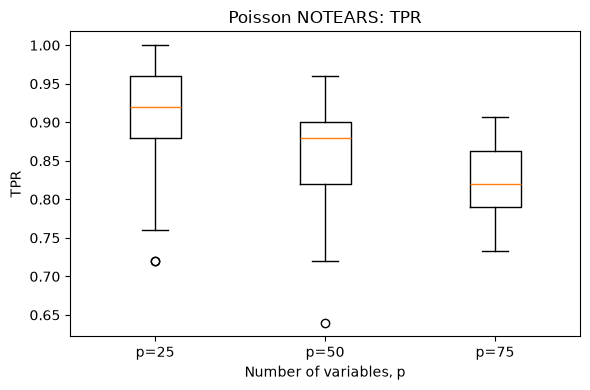

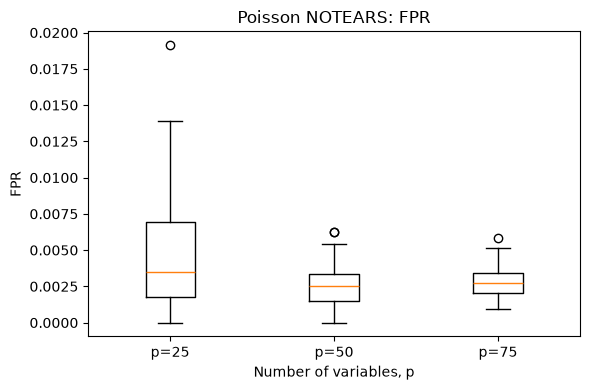

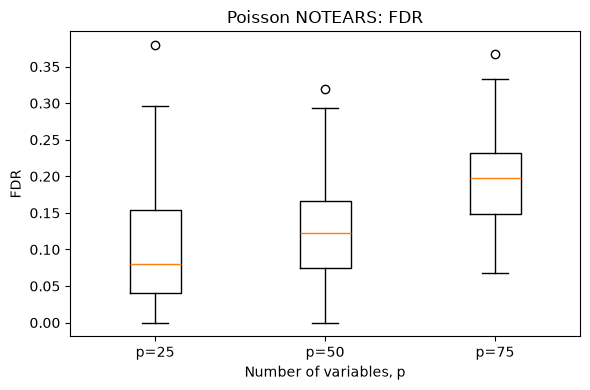

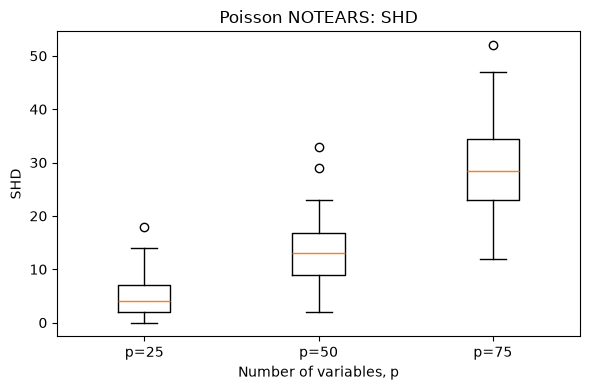

In [14]:
# ============================================================
# 9. Optional diagnostic plots
# ============================================================

levels = sorted(successful["p_setting"].unique())

for metric in ["TPR", "FPR", "FDR", "SHD"]:
    plot_data = [
        successful.loc[
            successful["p_setting"] == level, metric
        ].dropna().to_numpy()
        for level in levels
    ]

    labels = [f"p={int(level)}" for level in levels]

    plt.figure(figsize=(6, 4))
    plt.boxplot(plot_data, tick_labels=labels)
    plt.xlabel("Number of variables, p")
    plt.ylabel(metric)
    plt.title(f"Poisson NOTEARS: {metric}")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 12. Check completion status
# ============================================================

status_check = (
    results
    .groupby(["p_setting", "status"])
    .size()
    .reset_index(name="number_of_datasets")
)

display(status_check)


## Changing the seed set

Edit only `SEEDS_TO_RUN` in the configuration cell:

```python
SEEDS_TO_RUN = list(range(1, 11))   # seeds 1:10
SEEDS_TO_RUN = list(range(1, 51))   # seeds 1:50
SEEDS_TO_RUN = [2, 5, 12]           # selected seeds
SEEDS_TO_RUN = None                  # all available
```

The upper value in Python `range` is excluded, so `range(1, 11)` means
seeds 1 through 10.

## Parameter mapping

- \(p=25\): `lambda1=0.0009`, threshold `0.30`
- \(p=50\): `lambda1=0.0009`, threshold `0.40`
- \(p=75\): `lambda1=0.0020`, threshold `0.30`

The data are not scaled. The final table reports both true and estimated
DAG sizes.
